# GTSRB traffic sign classifier (PyTorch)

CNN for the German Traffic Sign Recognition Benchmark: 43 classes, 50×50 RGB input. The trained weights (`gtsrb_model.pth`) are used by the Telegram bot in `main.py`.

**Results:** validation accuracy 99.85% (20% of the training set), **test accuracy 98.97%** on the official GTSRB test set (12,630 images).

**Data:** `Train.csv`, `Test.csv` and the image folders from the GTSRB Kaggle release, unpacked to `/content/`.

**Notes**
- Training used no data augmentation: images are only resized to 50×50 and scaled to 0..1.
- `val_loss` in the training log is the loss of the last validation batch, not the mean over the whole validation set.
- Possible improvement: augmentation with small rotations, brightness and blur — but without horizontal flips, which turn "turn left" signs into "turn right" ones.

In [ ]:
from torch.utils.data import Dataset,DataLoader,random_split #PyTorch-та маалыматтар менен иштөө үчүн класстарды жана функцияларды импорттоо
from typing import Any,Tuple,Optional,Callable #Өзгөрмө түрлөрүн жана функцияларын аннотациялоо үчүн түрлөрүн импорттоо
import PIL #Сүрөттөр менен иштөө үчүн модулду импорттоо
import csv #CSV файлдар менен иштөө үчүн модулду импорттоо
import pathlib #Файл жолдору жана каталогдор менен иштөө үчүн модулду импорттоо
import torch #Машина үйрөнүү үчүн PyTorch китепкананы импорттоо
import torch.nn as nn #PyTorch нейрон тармак модулун импорттоо
from torch.optim import Adam,lr_scheduler #Adam оптимизаторду импорттоо
#PyTorch сүрөттөр үчүн трансформация топтомун импорттоо
from torchvision.transforms.v2 import ToTensor,Resize,Compose
import matplotlib.pyplot as plt #Графиктердин жардамы менен маалыматтарды визуалдаштыруу үчүн модулду импорттоо

In [ ]:
import zipfile
zip_file_name = 'Test.zip'

with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
    zip_ref.extractall('/content/')

In [ ]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [ ]:
class GTSRB(Dataset):
    def __init__(self,
                 root: str,
                 split: str,
                 transform: Optional[Callable] = None):
        self.base_folder = pathlib.Path(root)
        self.csv_file = self.base_folder / ('Train.csv' if split =='Train' else 'Test.csv')
        with open('/'+str(self.csv_file)) as csvfile:
           samples = [('/'+str(self.base_folder / row['Path']),int(row['ClassId']))
            for row in csv.DictReader(csvfile,delimiter=',',skipinitialspace=True)
                ]
        self.samples = samples
        self.split = split
        self.transform = transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, index: int) -> Tuple:
        path,classId =  self.samples[index]
        sample = PIL.Image.open(path).convert('RGB')
        if self.transform is not None:
            sample = self.transform(sample)
        return sample,classId

In [ ]:
# Обучение шло без аугментации: только сжатие до 50x50 и ToTensor (значения 0..1).
# Те же преобразования использует бот (main.py), поэтому они должны совпадать.
base_transforms = Compose([
    Resize([50,50]),
    ToTensor(),
])

In [ ]:
def train_test_split(dataset,train_size):

    train_size = int(train_size * len(dataset))
    test_size = int(len(dataset) - train_size)
    return random_split(dataset,[train_size,test_size])

In [ ]:
dataset = GTSRB(root='/content/',split="Train")
train_set,validation_set = train_test_split(dataset,train_size=0.8)
print(f'training size : {len(train_set)}, Validation size : {len(validation_set)}')

training size : 31367, Validation size : 7842


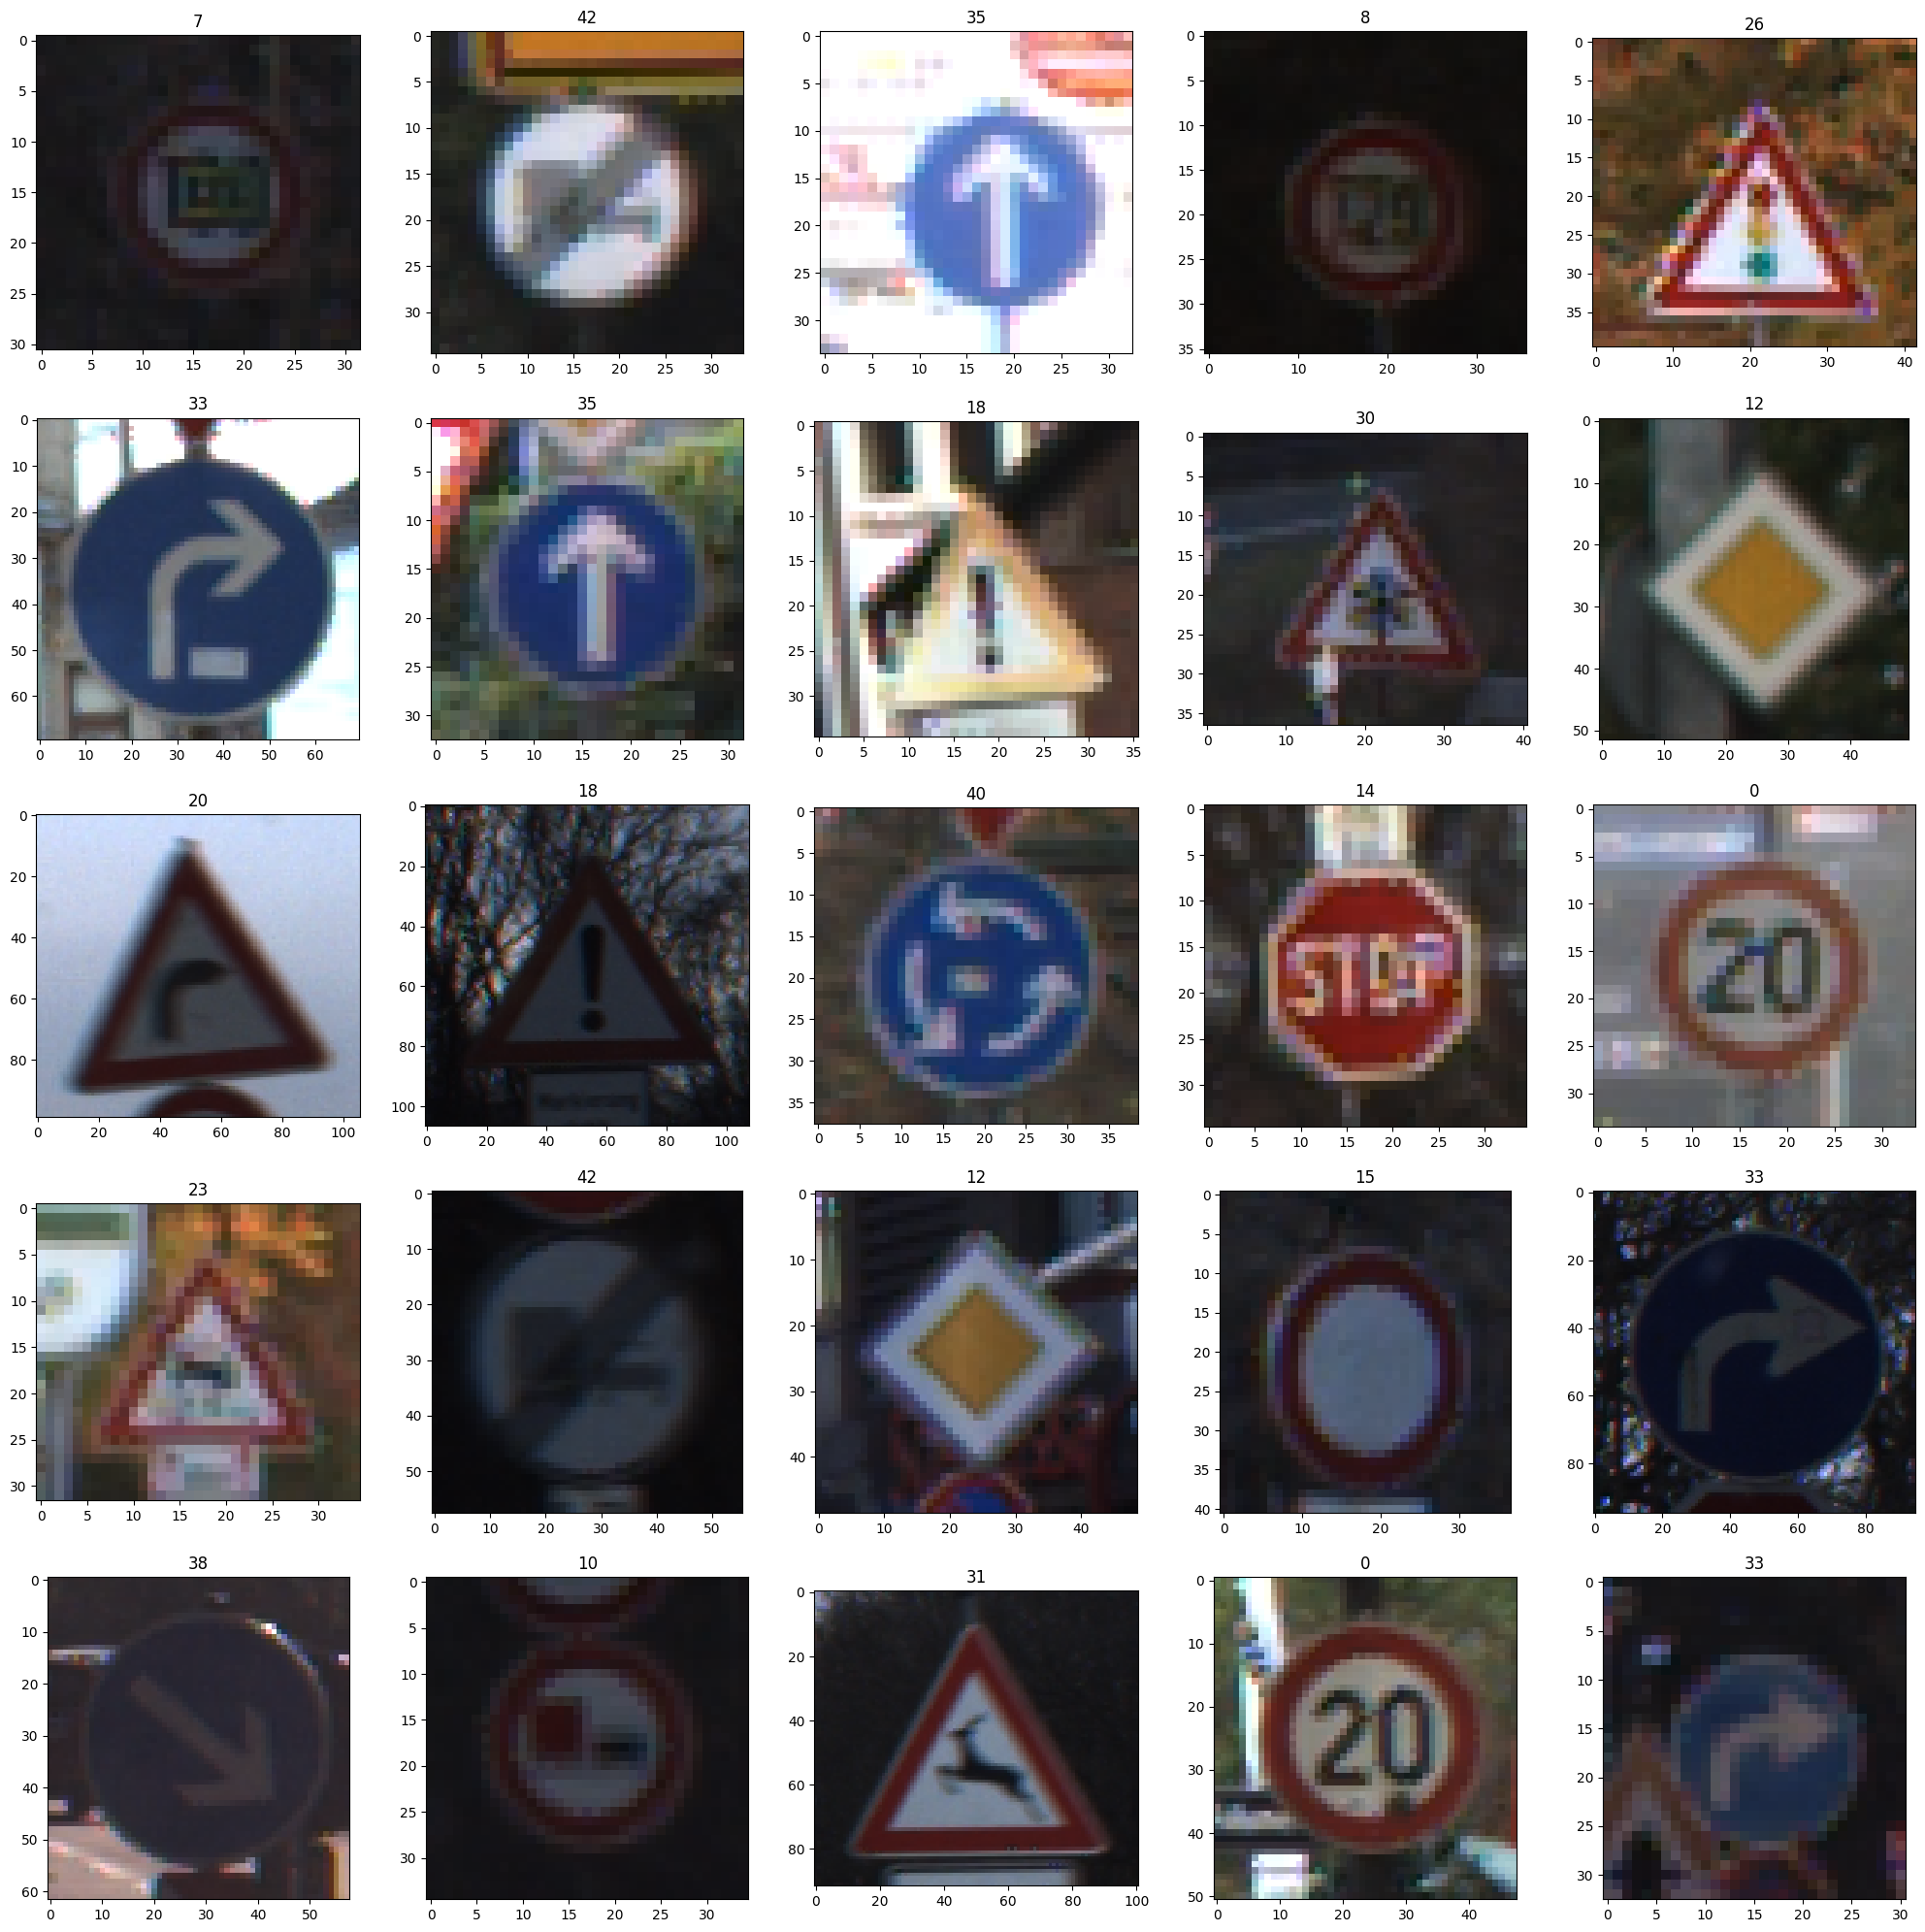

In [ ]:
plt.figure(figsize=(25,25))
for i in range(1,26):
    input,label = train_set[i]
    plt.subplot(5,5,i)
    plt.title(label)
    plt.imshow(input)


In [ ]:
# train_set и validation_set — части одного датасета, поэтому преобразования задаются один раз
dataset.transform = base_transforms
BATCH_SIZE = 64
train_loader = DataLoader(dataset=train_set,batch_size=BATCH_SIZE,shuffle=True)
validation_loader = DataLoader(dataset=validation_set,batch_size=BATCH_SIZE)

In [ ]:
class GTSRB_MODEL(nn.Module):
    def __init__(self,input_dim,output_dim):
        super(GTSRB_MODEL,self).__init__()
        self.input_dim = input_dim
        self.output_dim = output_dim
        self.metrics = {}

        self.flatten = nn.Flatten()

        self.dropout2 = nn.Dropout(0.2)
        self.dropout3 = nn.Dropout(0.3)

        self.relu = nn.ReLU()
        self.maxpool = nn.MaxPool2d(2)

        self.conv1 = nn.Conv2d(in_channels=3,out_channels=32,kernel_size=3,padding=1)
        self.conv2 = nn.Conv2d(in_channels=32,out_channels=64,kernel_size=3,padding=1)
        self.batchnorm1 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(in_channels=64,out_channels=128,kernel_size=3,padding=1)
        self.conv4 = nn.Conv2d(in_channels=128,out_channels=256,kernel_size=3,padding=1)
        self.batchnorm2 = nn.BatchNorm2d(256)

        self.conv5 = nn.Conv2d(in_channels=256,out_channels=512,kernel_size=3)
        self.conv6 = nn.Conv2d(in_channels=512,out_channels=1024,kernel_size=3)
        self.batchnorm3 = nn.BatchNorm2d(1024)

        self.l1 = nn.Linear(1024*4*4,512)
        self.l2 = nn.Linear(512,128)
        self.batchnorm4 = nn.LayerNorm(128)
        self.l3 = nn.Linear(128,output_dim)


    def forward(self,input):

        conv = self.conv1(input)
        conv = self.conv2(conv)
        batchnorm = self.relu(self.batchnorm1(conv))
        maxpool = self.maxpool(batchnorm)

        conv = self.conv3(maxpool)
        conv = self.conv4(conv)
        batchnorm = self.relu(self.batchnorm2(conv))
        maxpool = self.maxpool(batchnorm)

        conv = self.conv5(maxpool)
        conv = self.conv6(conv)
        batchnorm = self.relu(self.batchnorm3(conv))
        maxpool = self.maxpool(batchnorm)

        flatten = self.flatten(maxpool)
        dense_l1 = self.l1(flatten)
        dropout = self.dropout3(dense_l1)
        dense_l2 = self.l2(dropout)
        batchnorm = self.batchnorm4(dense_l2)
        dropout = self.dropout2(batchnorm)
        output = self.l3(dropout)
        return output

    def training_metrics(self,positives,data_size,loss):
        acc = positives/data_size
        return loss,acc

    def validation_metrics(self,validation_data,loss_function):
       data_size = len(validation_data)
       correct_predictions = 0
       total_samples = 0
       val_loss = 0
       model = self.eval()
       with torch.no_grad() :
        for step,(input,label) in enumerate(validation_data):
            input,label = input.to(device),label.to(device)
            prediction = model.forward(input)
            loss = loss_function(prediction,label)
            val_loss = loss.item()
            _,predicted = torch.max(prediction,1)
            correct_predictions += (predicted == label).sum().item()
            total_samples += label.size(0)

       val_acc = correct_predictions/total_samples

       return val_loss,val_acc

    def history(self):
        return self.metrics

    def compile(self,train_data,validation_data,epochs,loss_function,optimizer,learning_rate_scheduler):
        val_acc_list = []
        val_loss_list = []
        train_acc_list = []
        train_loss_list = []
        learning_rate_list = []
        print('training started ...')
        STEPS = len(train_data)
        for epoch in range(epochs):
            lr = optimizer.param_groups[0]["lr"]
            learning_rate_list.append(lr)
            correct_predictions = 0
            total_examples = 0
            loss = 0
            with tqdm.trange(STEPS) as progress:
                for step,(input,label) in enumerate(train_loader):
                    input,label = input.to(device),label.to(device)
                    prediction = self.forward(input)
                    _, predicted = torch.max(prediction, 1)
                    correct_predictions += (predicted == label).sum().item()
                    total_examples += label.size(0)
                    l = loss_function(prediction,label)
                    loss = l.item()
                    l.backward()
                    optimizer.step()
                    optimizer.zero_grad()
                    progress.colour = 'green'
                    progress.desc = f'Epoch [{epoch}/{EPOCHS}], Step [{step}/{STEPS}], Learning Rate [{lr}], Loss [{"{:.4f}".format(l)}], Accuracy [{"{:.4f}".format(correct_predictions/total_examples)}]'
                    progress.update(1)
            training_loss,training_acc = self.training_metrics(correct_predictions,total_examples,loss)
            train_acc_list.append(training_acc)
            train_loss_list.append(training_loss)
            val_loss, val_acc = self.validation_metrics(validation_data,loss_function)
            val_acc_list.append(val_acc)
            val_loss_list.append(val_loss)
            print(f'val_accuracy [{val_acc}], val_loss [{val_loss}]')
            learning_rate_scheduler.step()
        metrics_dict = {
                'train_acc':train_acc_list,
                'train_loss':train_loss_list,
                'val_acc':val_acc_list,
                'val_loss':val_loss_list,
                'learning_rate':optimizer.param_groups[0]["lr"]
            }
        self.metrics = metrics_dict
        print('training complete !')



In [ ]:
import tqdm
EPOCHS = 20
LEARNING_RATE = 0.0008
INPUT_DIM = 3*50*50
OUTPUT_DIM = 43
model = GTSRB_MODEL(INPUT_DIM,OUTPUT_DIM).to(device)
optimizer = Adam(params=model.parameters(),lr=LEARNING_RATE)
lr_s = lr_scheduler.LinearLR(optimizer,start_factor=1.0,end_factor=0.5,total_iters=10)
loss = nn.CrossEntropyLoss()

In [ ]:
model.compile(train_data=train_loader,validation_data=validation_loader,epochs=EPOCHS,loss_function=loss,optimizer=optimizer,learning_rate_scheduler=lr_s)

training started ...


Epoch [0/20], Step [490/491], Learning Rate [0.0008], Loss [0.0972], Accuracy [0.7548]: 100%|██████████| 491/491 [00:51<00:00,  9.62it/s]


val_accuracy [0.9875031879622546], val_loss [0.09739844501018524]


Epoch [1/20], Step [490/491], Learning Rate [0.00076], Loss [0.0118], Accuracy [0.9919]: 100%|██████████| 491/491 [00:41<00:00, 11.78it/s]


val_accuracy [0.9960469268043867], val_loss [0.018416129052639008]


...

val_accuracy [0.998342259627646], val_loss [4.563198672258295e-05]


Epoch [18/20], Step [490/491], Learning Rate [0.0004000000000000001], Loss [0.0000], Accuracy [1.0000]: 100%|██████████| 491/491 [00:42<00:00, 11.54it/s]


val_accuracy [0.998342259627646], val_loss [4.110644294996746e-05]


Epoch [19/20], Step [490/491], Learning Rate [0.0004000000000000001], Loss [0.0000], Accuracy [1.0000]: 100%|██████████| 491/491 [00:42<00:00, 11.59it/s]


val_accuracy [0.9984697781178271], val_loss [3.448867573752068e-05]
training complete !


In [ ]:
testdata = GTSRB(root='/content/',split='Test',transform=base_transforms)
print('testing size :',len(testdata))
test_dataloader = DataLoader(testdata)

In [ ]:
from sklearn.metrics import accuracy_score
y_pred = []
y_true = []
model = model.eval().to(device)
with tqdm.tqdm(colour='red',total=len(test_dataloader)) as progress:
  with torch.no_grad() :
    for id,(input,label) in enumerate(iter(test_dataloader)):
        input,label = input.to(device),label.to(device)
        y_true.append(label.item())
        prediction = model.forward(input)
        _,prediction = torch.max(prediction,1)
        y_pred.append(prediction.item())
        progress.desc = f'Test Accuracy : {accuracy_score(y_true,y_pred)} '
        progress.update(1)


Test Accuracy : 0.9897070467141726 : 100%|██████████| 12630/12630 [01:28<00:00, 141.98it/s]


In [ ]:
torch.save(model.state_dict(), '/content/gtsrb_model.pth')
